# Part 3: estimating washing-machine power

Estimate one-minute washing-machine power from current/past whole-home aggregate power. Compare **always-off, Ridge, Random Forest and HistGradientBoosting** using a small validation-only search.

Train Houses **2, 3, 8, 9**; validate on **5**; evaluate **7 and 10** separately. These evaluation homes have been examined before, so both are **retrospective holdouts**, not blind tests. Keep the split fixed and never choose parameters from their results.

Use January–March 2015, UTC; behaviour/plots use UK local time. Read the supplied cleaned REFIT README for channel assignments. Run this notebook using **Jupyter → Restart & Run All** from the project folder. Dependencies: NumPy, pandas, Matplotlib, scikit-learn, threadpoolctl and Jupyter. Only a comparison CSV, the selected model with its ordered feature names, and four figures are exported.

## 1. Imports and paths

Change `ROOT` if necessary. Reuse matching Part 2 exports for Houses 2, 3 and 5; load the other homes from the official cleaned CSVs. If those exports are unavailable, the same Part 2 cleaning rules prepare them directly from the official source. No previous Part 3 output is needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import precision_score, recall_score, f1_score
from threadpoolctl import threadpool_limits
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
CLEAN_DIR = ROOT / 'clean'
PART2_DIR = ROOT / 'outputs/part2'
FIGURE_DIR = ROOT / 'figures/part3'
RESULT_DIR = ROOT / 'results'
TRAIN_HOUSES = [2, 3, 8, 9]
VALIDATION_HOUSE = 5
TEST_HOUSES = [7, 10]
CHANNELS = {2: 'Appliance2', 3: 'Appliance6', 5: 'Appliance3',
            7: 'Appliance5', 8: 'Appliance4', 9: 'Appliance3', 10: 'Appliance5'}
START = pd.Timestamp('2015-01-01', tz='UTC')
END = pd.Timestamp('2015-04-01', tz='UTC')
GRID = pd.date_range(START, END, freq='1min', inclusive='left')
LOCAL_TZ = 'Europe/London'
ACTIVE_W = 20
SEED = 42
thread_limit = threadpool_limits(limits=4)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
assert len(set(TRAIN_HOUSES + [VALIDATION_HOUSE] + TEST_HOUSES)) == 7

## 2. Load and check the data

Dedicated washing-machine mappings above match the supplied README; separate washer-dryers are excluded. Apply the Part 2 rules: stable time sorting, last non-missing power per duplicate Unix timestamp, maximum Issues flag, impossible readings masked, and one-minute means. Keep the full UTC grid and add **no interpolation**.

An Issues flag means the submeter sum exceeds aggregate; retain flagged minutes and report them, as permitted by the README. Removing them all can fragment washing cycles. The official release has already forward-filled short gaps and zeroed some missing/invalid readings. Therefore **zero does not prove switched-off time, and non-missing coverage is not verified sensor uptime**. This analysis follows Part 2's cleaned-release interpretation, without adding aggressive raw-data filtering. Source uncertainty remains a limitation.

In [2]:
def load_house(house):
    power_path = PART2_DIR / f'house{house}_1min.csv.gz'
    quality_path = PART2_DIR / f'house{house}_quality.csv.gz'
    if house in [2, 3, 5] and power_path.exists() and quality_path.exists():
        power = pd.read_csv(power_path, index_col=0, parse_dates=True)
        quality = pd.read_csv(quality_path, index_col=0, parse_dates=True)
        flags = quality['issue_flagged']
        source = 'Part 2 export'
    else:
        channel = CHANNELS[house]
        path = CLEAN_DIR / f'CLEAN_House{house}.csv'
        if not path.is_file():
            raise FileNotFoundError(f'Provide the official cleaned dataset at {path}')
        pieces = []
        for chunk in pd.read_csv(path, usecols=['Unix', 'Aggregate', channel, 'Issues'], chunksize=500_000):
            take = chunk['Unix'].between(START.timestamp(), END.timestamp(), inclusive='left')
            if take.any():
                pieces.append(chunk.loc[take])
        if not pieces:
            raise ValueError(f'House {house}: no readings in the selected period')
        raw = pd.concat(pieces).rename(columns={channel: 'washing_machine'})
        raw = raw.sort_values('Unix', kind='stable').groupby('Unix').agg(
            {'Aggregate': 'last', 'washing_machine': 'last', 'Issues': 'max'})
        raw.index = pd.to_datetime(raw.index, unit='s', utc=True)
        power = raw[['Aggregate', 'washing_machine']].astype('float32')
        power = power.mask((power < 0) | ~np.isfinite(power))
        power['washing_machine'] = power['washing_machine'].mask(power['washing_machine'] > 4000)
        power = power.resample('1min').mean().reindex(GRID)
        flags = raw['Issues'].ne(0).resample('1min').max().reindex(GRID).eq(True)
        source = path.name
    assert power.index.equals(GRID) and flags.index.equals(GRID)
    assert list(power.columns) == ['Aggregate', 'washing_machine']
    assert flags.isin([True, False]).all()
    assert not np.isinf(power).any().any() and not (power < 0).any().any()
    assert power.washing_machine.dropna().le(4000).all()
    power.index.name = 'timestamp_utc'
    return power, flags.astype(bool), source

power_data, issue_flags, quality_rows = {}, {}, []
def add_house(house):
    power, flags, source = load_house(house)
    power_data[house], issue_flags[house] = power, flags
    target = power.washing_machine.dropna()
    quality_rows.append({'house': house, 'source': source, 'grid_minutes': len(power),
                         'joint_available_minutes': int(power.notna().all(axis=1).sum()),
                         'missing_target_minutes': int(power.washing_machine.isna().sum()),
                         'zero_percent_of_available': 100 * target.eq(0).mean(),
                         'issue_minutes': int(flags.sum())})

# Evaluation measurements are loaded only after the model has been selected.
for house in TRAIN_HOUSES + [VALIDATION_HOUSE]:
    add_house(house)
display(pd.DataFrame(quality_rows).set_index('house').round(2))

,source,grid_minutes,joint_available_minutes,missing_target_minutes,zero_percent_of_available,issue_minutes
house,,,,,,
2,Part 2 export,129600,124680,4920,94.50,1852
3,Part 2 export,129600,124952,4648,92.45,4479
8,CLEAN_House8.csv,129600,124992,4608,80.31,1682
9,CLEAN_House9.csv,129600,125009,4591,91.56,2981
5,Part 2 export,129600,124852,4748,75.73,5725


## 3. Household splitting and 12 causal features

Use aggregate power now; lags of 1, 5, 15 and 60 minutes; trailing 15/60-minute mean and standard deviation; one-minute change; local hour and weekday. Lags/context distinguish short switching from sustained activity; calendar features provide a simple usage prior. Ridge scales these correlated inputs using training data only.

Build features separately per household **before** dropping missing rows. Require all 61 aggregate minutes from t−60 through t; an outage must never become a compressed sequence of adjacent observations. Only the current appliance target needs to be available. No appliance history, household ID, Issues flag or future value is an input. This is prediction at the **end of the current minute**, not forecasting.

In [3]:
def make_features(aggregate):
    features = pd.DataFrame({'aggregate_W': aggregate})
    for lag in [1, 5, 15, 60]:
        features[f'lag_{lag}'] = aggregate.shift(lag)
    for window in [15, 60]:
        history = aggregate.rolling(window, min_periods=window)
        features[f'mean_{window}'] = history.mean()
        features[f'std_{window}'] = history.std()
    features['change_1'] = aggregate.diff()
    local = aggregate.index.tz_convert(LOCAL_TZ)
    features['hour'] = local.hour
    features['weekday'] = local.day_of_week
    complete = aggregate.rolling(61, min_periods=61).count().eq(61)
    return features.where(complete)

def prepare_house(house):
    table = make_features(power_data[house].Aggregate)
    table['target_W'] = power_data[house].washing_machine
    table = table.dropna()
    if table.empty:
        raise ValueError(f'House {house}: no complete feature/target rows')
    return table

samples = {h: prepare_house(h) for h in TRAIN_HOUSES + [VALIDATION_HOUSE]}
feature_columns = [c for c in samples[VALIDATION_HOUSE] if c != 'target_W']
train = pd.concat([samples[h] for h in TRAIN_HOUSES], keys=TRAIN_HOUSES, names=['house', 'timestamp_utc'])
validation = samples[VALIDATION_HOUSE]
X_train, y_train = train[feature_columns], train.target_W
print(f'{len(feature_columns)} features; {len(train):,} training and {len(validation):,} validation minutes')
print(f'Active training minutes: {y_train.gt(ACTIVE_W).mean():.1%}')

12 features; 494,612 training and 121,077 validation minutes
Active training minutes: 4.3%


## 4. Metrics and always-off baseline

MAE measures average watt error; RMSE emphasises large errors. Precision/recall/F1 use actual and predicted power **>20 W**, consistently with Part 2. These are minute-level activity metrics, not cycle recall. Always-off has F1 zero even when MAE is low.

Energy is `sum(minute W)/60,000` kWh, over identical eligible minutes. Net bias can cancel opposite errors. Daily error instead sums absolute UK-local daily energy differences and divides by total actual energy; partial days remain partial observations.

All regressors use the same non-negative, aggregate-capped predictions. This can underestimate appliance labels above aggregate because of asynchronous meters; targets themselves are never capped. No output suppression threshold is tuned.

In [4]:
def evaluate(actual, predicted):
    y = actual.to_numpy(dtype=float)
    p = np.asarray(predicted, dtype=float)
    assert len(y) > 0 and y.shape == p.shape and np.isfinite(y).all() and np.isfinite(p).all()
    assert actual.index.is_unique and actual.index.is_monotonic_increasing
    on, predicted_on = y > ACTIVE_W, p > ACTIVE_W
    daily = pd.DataFrame({'actual': y, 'predicted': p}, index=actual.index.tz_convert(LOCAL_TZ))
    daily = daily.resample('1D').sum(min_count=1)
    energy = y.sum()
    return {'minutes': len(y), 'MAE_W': np.abs(y-p).mean(), 'RMSE_W': np.sqrt(np.mean((y-p)**2)),
            'precision': precision_score(on, predicted_on, zero_division=0),
            'recall': recall_score(on, predicted_on, zero_division=0),
            'F1': f1_score(on, predicted_on, zero_division=0),
            'actual_kWh': energy/60000, 'predicted_kWh': p.sum()/60000,
            'energy_bias_percent': 100*(p.sum()-energy)/energy if energy else np.nan,
            'daily_energy_error_percent': 100*(daily.predicted-daily.actual).abs().sum()/energy if energy else np.nan}

def predict_power(model, table):
    if model is None:
        return np.zeros(len(table))
    return np.clip(model.predict(table[feature_columns]), 0, table.aggregate_W.to_numpy())

off_validation = evaluate(validation.target_W, np.zeros(len(validation)))
display(pd.DataFrame([off_validation], index=['AlwaysOff']).round(3))

,minutes,MAE_W,RMSE_W,precision,recall,F1,actual_kWh,predicted_kWh,energy_bias_percent,daily_energy_error_percent
AlwaysOff,121077,38.713,218.377,0.0,0.0,0.0,78.12,0.0,-100.0,100.0


## 5. Establish defaults, then tune a few settings

Use bounded reference settings suitable for this dataset: Ridge alpha=1; RF 60 trees, depth ≤14, leaf size 20, 60,000 bootstrap rows/tree; HGB 150 iterations, 15 leaves, minimum leaf size 100. These are declared reference settings, not every scikit-learn constructor default.

First compare these three with always-off. Then test one alternative per family: Ridge alpha=100, RF leaf size=100, HGB leaves=31. If measured training activity is below 10%, also test HGB with active-minute weight 5 to check whether imbalance handling helps. Do not rebalance validation/evaluation. Disable HGB internal early stopping to avoid a hidden random time split. Maximum: **seven fitted estimators**.

**Selection rule, declared before evaluation:** require validation RMSE and daily energy error both below always-off, then choose the highest F1, breaking exact ties by MAE and configuration name. If no regressor passes, keep always-off. This gives activity detection priority while requiring useful power/energy estimates, without a weighted composite score. An alternative replaces its family's reference only if it passes those guards and improves validation F1 by at least 0.01; this practical margin avoids adopting tiny gains.

In [5]:
models, validation_rows = {}, []
def fit_candidate(name, family, model, active_weight=1):
    weights = np.where(y_train > ACTIVE_W, active_weight, 1.)
    if family == 'Ridge':
        model.fit(X_train, y_train, ridge__sample_weight=weights)
    else:
        model.fit(X_train, y_train, sample_weight=weights)
    models[name] = model
    row = evaluate(validation.target_W, predict_power(model, validation))
    validation_rows.append(dict(row, configuration=name, family=family))

rf_settings = dict(n_estimators=60, max_depth=14, max_samples=min(60000, len(train)),
                   n_jobs=4, random_state=SEED)
hgb_settings = dict(learning_rate=.06, max_iter=150, min_samples_leaf=100,
                    l2_regularization=10, early_stopping=False, random_state=SEED)
fit_candidate('Ridge_reference', 'Ridge', make_pipeline(StandardScaler(), Ridge(alpha=1)))
fit_candidate('RF_reference', 'RandomForest', RandomForestRegressor(min_samples_leaf=20, **rf_settings))
fit_candidate('HGB_reference', 'HGB', HistGradientBoostingRegressor(max_leaf_nodes=15, **hgb_settings))
validation_rows.append(dict(off_validation, configuration='AlwaysOff', family='AlwaysOff'))
models['AlwaysOff'] = None
display(pd.DataFrame(validation_rows).set_index('configuration')[['MAE_W','RMSE_W','precision','recall','F1','daily_energy_error_percent']].round(3))

,MAE_W,RMSE_W,precision,recall,F1,daily_energy_error_percent
configuration,,,,,,
Ridge_reference,61.584,207.303,0.174,0.772,0.283,98.022
RF_reference,50.786,207.160,0.269,0.401,0.322,89.714
HGB_reference,51.187,210.881,0.269,0.328,0.296,90.820
AlwaysOff,38.713,218.377,0.000,0.000,0.000,100.000


In [6]:
fit_candidate('Ridge_alpha100', 'Ridge', make_pipeline(StandardScaler(), Ridge(alpha=100)))
fit_candidate('RF_leaf100', 'RandomForest', RandomForestRegressor(min_samples_leaf=100, **rf_settings))
fit_candidate('HGB_leaves31', 'HGB', HistGradientBoostingRegressor(max_leaf_nodes=31, **hgb_settings))
if y_train.gt(ACTIVE_W).mean() < .10:
    fit_candidate('HGB_weight5', 'HGB', HistGradientBoostingRegressor(max_leaf_nodes=15, **hgb_settings), active_weight=5)
validation_results = pd.DataFrame(validation_rows).set_index('configuration')
validation_results['passes_guards'] = ((validation_results.RMSE_W < off_validation['RMSE_W']) &
                                      (validation_results.daily_energy_error_percent < 100))
reference_names = {'Ridge': 'Ridge_reference', 'RandomForest': 'RF_reference', 'HGB': 'HGB_reference'}
winner_names = ['AlwaysOff']
for family, reference in reference_names.items():
    alternatives = validation_results[(validation_results.family == family) & validation_results.passes_guards]
    alternatives = alternatives[alternatives.F1 >= validation_results.loc[reference, 'F1'] + .01]
    if alternatives.empty:
        winner_names.append(reference)
    else:
        winner_names.append(alternatives.sort_values(['F1','MAE_W','configuration'], ascending=[False,True,True]).index[0])
family_results = validation_results.loc[winner_names]
eligible = family_results[family_results.passes_guards]
selected_name = 'AlwaysOff' if eligible.empty else eligible.sort_values(
    ['F1','MAE_W','configuration'], ascending=[False,True,True]).index[0]
selected_model = models[selected_name]
display(validation_results[['family','MAE_W','RMSE_W','precision','recall','F1','energy_bias_percent','daily_energy_error_percent','passes_guards']].round(3))
print('Frozen validation selection:', selected_name)

,family,MAE_W,RMSE_W,precision,recall,F1,energy_bias_percent,daily_energy_error_percent,passes_guards
configuration,,,,,,,,,
Ridge_reference,Ridge,61.584,207.303,0.174,0.772,0.283,-8.979,98.022,True
RF_reference,RandomForest,50.786,207.160,0.269,0.401,0.322,-39.612,89.714,True
HGB_reference,HGB,51.187,210.881,0.269,0.328,0.296,-39.314,90.820,True
AlwaysOff,AlwaysOff,38.713,218.377,0.000,0.000,0.000,-100.000,100.000,False
Ridge_alpha100,Ridge,61.588,207.299,0.173,0.772,0.283,-8.958,98.022,True
RF_leaf100,RandomForest,51.807,206.964,0.264,0.401,0.318,-36.851,89.828,True
HGB_leaves31,HGB,49.890,209.213,0.274,0.347,0.306,-42.390,88.957,True
HGB_weight5,HGB,71.196,219.734,0.195,0.626,0.297,41.513,106.374,False


Frozen validation selection: RF_reference


## 6. Final household evaluation

Load Houses 7 and 10 only after selection. Keep all family winners fixed; never refit on validation or pick a different winner using evaluation metrics. Report each home separately. Coverage and Issues strata describe which observations were scored. These reused homes cannot provide a prospective blind estimate.

In [7]:
for house in TEST_HOUSES:
    add_house(house)
    samples[house] = prepare_house(house)

predictions, metric_rows = {}, []
for house in [VALIDATION_HOUSE] + TEST_HOUSES:
    table = samples[house]
    frame = table[['target_W','aggregate_W']].rename(columns={'target_W':'actual_W'}).copy()
    split = 'validation' if house == VALIDATION_HOUSE else f'test_house{house}'
    for name in winner_names:
        frame[name] = predict_power(models[name], table)
        metric_rows.append(dict(evaluate(frame.actual_W, frame[name]), house=house, split=split,
                                model=validation_results.loc[name,'family'], configuration=name))
    predictions[house] = frame
metrics = pd.DataFrame(metric_rows)
metric_columns = ['MAE_W','RMSE_W','precision','recall','F1','energy_bias_percent','daily_energy_error_percent']
display(metrics.set_index(['split','model'])[metric_columns].round(3))
quality_summary = pd.DataFrame(quality_rows).set_index('house')
quality_summary['eligible_minutes'] = pd.Series({h:len(t) for h,t in samples.items()})
quality_summary['eligible_percent'] = 100*quality_summary.eligible_minutes/len(GRID)
display(quality_summary.round(2))
issue_rows = []
for house in TEST_HOUSES:
    frame = predictions[house]
    flags = issue_flags[house].reindex(frame.index)
    for flag in [False, True]:
        group = frame.loc[flags.eq(flag)]
        if not group.empty:
            issue_rows.append(dict(evaluate(group.actual_W, group[selected_name]), house=house, issue_flagged=flag))
display(pd.DataFrame(issue_rows)[['house','issue_flagged','minutes','F1','MAE_W','daily_energy_error_percent']].round(3))

MAE_W   RMSE_W  precision  recall     F1  \
split        model                                                     
validation   AlwaysOff     38.713  218.377      0.000   0.000  0.000   
             Ridge         61.584  207.303      0.174   0.772  0.283   
             RandomForest  50.786  207.160      0.269   0.401  0.322   
             HGB           51.187  210.881      0.269   0.328  0.296   
test_house7  AlwaysOff     41.418  261.390      0.000   0.000  0.000   
             Ridge         52.390  233.755      0.273   0.708  0.394   
             RandomForest  49.051  219.490      0.408   0.771  0.533   
             HGB           49.881  218.693      0.377   0.590  0.460   
test_house10 AlwaysOff     27.481  195.309      0.000   0.000  0.000   
             Ridge         49.752  177.460      0.123   0.557  0.201   
             RandomForest  42.479  172.791      0.305   0.712  0.427   
             HGB           43.316  175.887      0.283   0.542  0.372   

                           energy_bias_percent  daily_energy_error_percent  
split        model                                                          
validation   AlwaysOff                -100.000                     100.000  
             Ridge                      -8.979                      98.022  
             RandomForest              -39.612                      89.714  
             HGB                       -39.314                      90.820  
test_house7  AlwaysOff                -100.000                     100.000  
             Ridge                     -38.038                      46.178  
             RandomForest              -28.286                      40.913  
             HGB                       -27.712                      40.782  
test_house10 AlwaysOff                -100.000                     100.000  
             Ridge                      21.307                      88.548  
             RandomForest               19.427                      75.677  
             HGB                        19.192                      75.553

,source,grid_minutes,joint_available_minutes,missing_target_minutes,zero_percent_of_available,issue_minutes,eligible_minutes,eligible_percent
house,,,,,,,,
2,Part 2 export,129600,124680,4920,94.50,1852,122939,94.86
3,Part 2 export,129600,124952,4648,92.45,4479,123701,95.45
8,CLEAN_House8.csv,129600,124992,4608,80.31,1682,123775,95.51
9,CLEAN_House9.csv,129600,125009,4591,91.56,2981,124197,95.83
5,Part 2 export,129600,124852,4748,75.73,5725,121077,93.42
7,CLEAN_House7.csv,129600,124369,5231,68.51,4759,123373,95.20
10,CLEAN_House10.csv,129600,121922,7678,92.15,1055,119868,92.49


,house,issue_flagged,minutes,F1,MAE_W,daily_energy_error_percent
0,7,False,118669,0.543,41.030,47.316
1,7,True,4704,0.484,251.396,87.040
2,10,False,118837,0.420,42.115,75.660
3,10,True,1031,0.645,84.400,79.815


## 7. Actual versus predicted

For each evaluation home, illustrate the active local day closest to median eligible-day energy among days with ≥90% coverage. If none qualify, use the best-covered active day and disclose the fallback. This target-informed illustration is chosen **after evaluation**, never for tuning. Blank intervals are unavailable, not zero predictions. Colours: grey aggregate, teal measured washer, orange prediction.

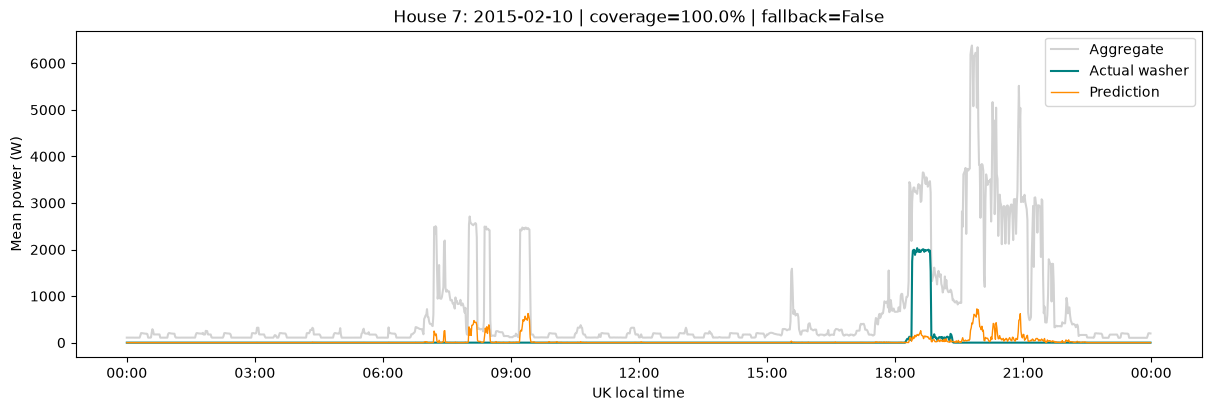

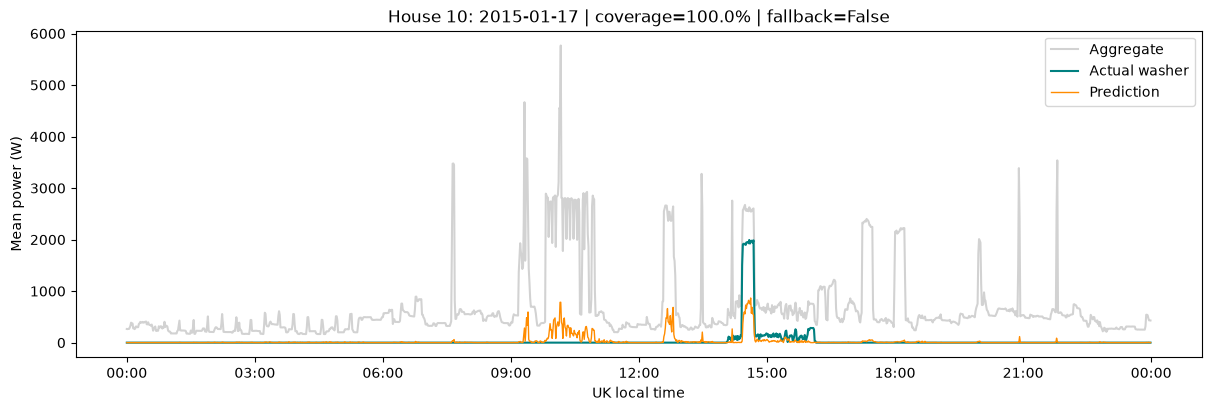

In [8]:
for house in TEST_HOUSES:
    frame = predictions[house].tz_convert(LOCAL_TZ)
    daily = frame.actual_W.resample('1D').agg(['count','sum'])
    expected = pd.Series([(d+pd.DateOffset(days=1)-d).total_seconds()/60 for d in daily.index], index=daily.index)
    coverage = daily['count']/expected
    pool = daily[(daily['sum'] > 0) & (coverage >= .90)]
    fallback = pool.empty
    if fallback:
        active = daily[daily['sum'] > 0]
        pool = active[coverage.reindex(active.index).eq(coverage.reindex(active.index).max())]
    if pool.empty:
        raise ValueError(f'House {house}: no active day available to plot')
    day = (pool['sum']-pool['sum'].median()).abs().idxmin()
    index = pd.date_range(day, day+pd.DateOffset(days=1), freq='1min', inclusive='left')
    trace = frame.reindex(index)
    fig, ax = plt.subplots(figsize=(12,4), layout='constrained')
    ax.plot(trace.index, trace.aggregate_W, color='grey', alpha=.35, label='Aggregate')
    ax.plot(trace.index, trace.actual_W, color='teal', label='Actual washer')
    ax.plot(trace.index, trace[selected_name], color='darkorange', label='Prediction', linewidth=1)
    ax.set(title=f'House {house}: {day.date()} | coverage={coverage.loc[day]:.1%} | fallback={fallback}',
           ylabel='Mean power (W)', xlabel='UK local time')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=LOCAL_TZ))
    ax.legend()
    fig.savefig(FIGURE_DIR/f'test_house{house}_actual_vs_predicted.png', dpi=150)
    plt.show()

## 8. Brief failure analysis

For each evaluation home, show a false-positive and a missed-usage example centred on the largest corresponding watt error. These are deliberately difficult windows; the metric table supplies overall rates. A false positive assigns washer activity while its meter is ≤20 W. A missed minute predicts ≤20 W during measured activity. Similar heating loads, low-power phases and different programmes are plausible explanations; these plots cannot identify the interfering appliance.

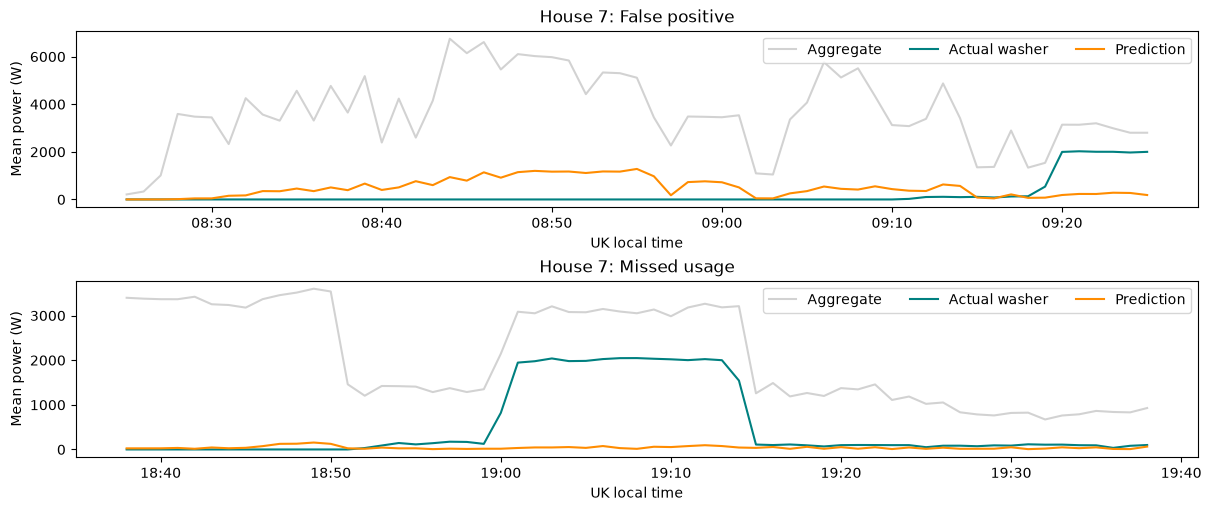

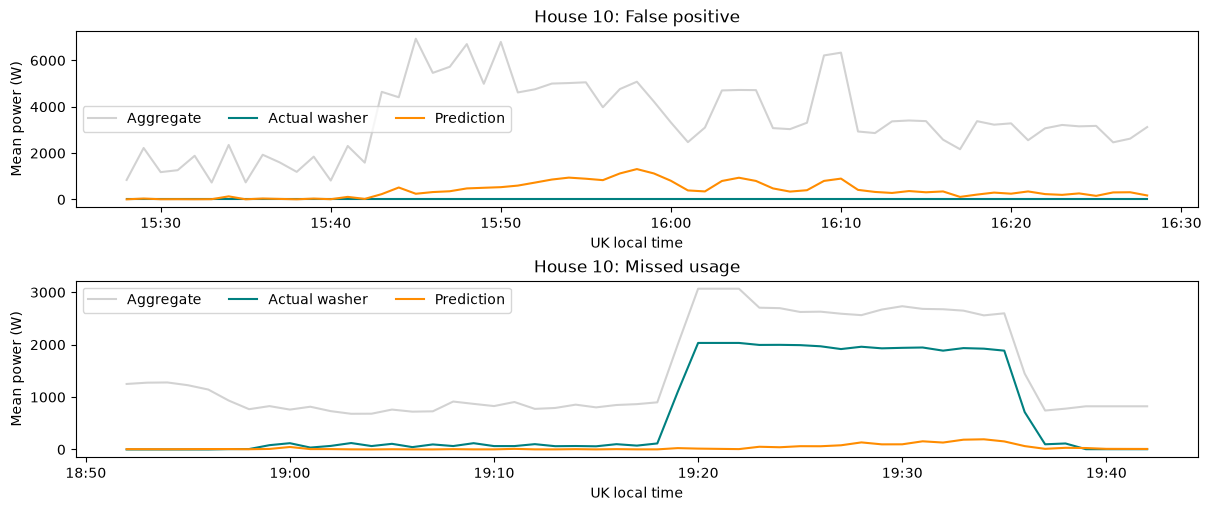

,false_positive_minutes,missed_minutes
house,,
7,11541,2358
10,14023,2492


In [9]:
failure_rows = []
for house in TEST_HOUSES:
    frame = predictions[house].tz_convert(LOCAL_TZ)
    actual_on, predicted_on = frame.actual_W.gt(ACTIVE_W), frame[selected_name].gt(ACTIVE_W)
    false_positive = ~actual_on & predicted_on
    missed = actual_on & ~predicted_on
    failure_rows.append({'house':house, 'false_positive_minutes':int(false_positive.sum()),
                         'missed_minutes':int(missed.sum())})
    fig, axes = plt.subplots(2,1,figsize=(12,5),layout='constrained')
    for ax, mask, label in [(axes[0],false_positive,'False positive'),(axes[1],missed,'Missed usage')]:
        if mask.any():
            centre = (frame.loc[mask,selected_name]-frame.loc[mask,'actual_W']).abs().idxmax()
            index = pd.date_range(centre-pd.Timedelta(minutes=30), centre+pd.Timedelta(minutes=30), freq='1min')
            window = frame.reindex(index)
            ax.plot(window.index, window.aggregate_W, color='grey', alpha=.35, label='Aggregate')
            ax.plot(window.index, window.actual_W, color='teal', label='Actual washer')
            ax.plot(window.index, window[selected_name], color='darkorange', label='Prediction')
            ax.legend(ncol=3)
        else:
            ax.text(.5,.5,f'No {label.lower()} minutes',ha='center',transform=ax.transAxes)
        ax.set(title=f'House {house}: {label}',ylabel='Mean power (W)',xlabel='UK local time')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M',tz=LOCAL_TZ))
    fig.savefig(FIGURE_DIR/f'test_house{house}_failure_windows.png',dpi=150)
    plt.show()
display(pd.DataFrame(failure_rows).set_index('house'))

## 9. Final checks and essential export

Keep basic checks for household separation, causal/missing-history behaviour, prediction bounds and energy accounting. Save the model-comparison table and selected model with its ordered feature names; tuning results, coverage and error analysis remain in notebook outputs. No runner, hashes, manifests or prediction exports are needed. Reload `results/washing_machine_model.joblib` with joblib; use `feature_names` to order the engineered inputs and `predict_power` for the same non-negative, aggregate-capped output. Re-running training in this notebook regenerates the figures and metrics.

In [10]:
# Future observations must not change earlier features, and gaps must block history.
index = pd.date_range(START, periods=160, freq='1min')
example = pd.Series(np.arange(160.), index=index)
changed = example.copy()
changed.iloc[100:] = 9999
pd.testing.assert_frame_equal(make_features(example).iloc[:100], make_features(changed).iloc[:100])
example.iloc[70] = np.nan
assert make_features(example).iloc[70:131].isna().all(axis=1).all()
# Equal and opposite daily errors must not cancel in daily energy error.
index = pd.date_range(START, periods=2880, freq='1min')
check = evaluate(pd.Series(100.,index=index), np.r_[np.full(1440,200.),np.zeros(1440)])
assert np.isclose(check['energy_bias_percent'],0) and np.isclose(check['daily_energy_error_percent'],100)
for house, frame in predictions.items():
    assert frame.index.equals(samples[house].index)
    for name in winner_names:
        assert np.isfinite(frame[name]).all()
        assert frame[name].between(0,frame.aggregate_W+1e-6).all()
metrics.to_csv(RESULT_DIR/'evaluation_metrics.csv',index=False)
saved = pd.read_csv(RESULT_DIR/'evaluation_metrics.csv')
np.testing.assert_allclose(saved[metric_columns], metrics[metric_columns])
print('Checks passed. Exported one comparison CSV and four figures.')

# Save the validation-selected model with the feature order required for inference.
import joblib
model_bundle = {'model': selected_model, 'feature_names': list(feature_columns),
                'model_name': selected_name}
model_path = RESULT_DIR / 'washing_machine_model.joblib'
joblib.dump(model_bundle, model_path)
loaded_bundle = joblib.load(model_path)
assert loaded_bundle['feature_names'] == feature_columns
sample = validation[loaded_bundle['feature_names']].iloc[:100]
np.testing.assert_allclose(predict_power(loaded_bundle['model'], sample),
                           predict_power(selected_model, sample), rtol=1e-12, atol=1e-12)
print('Saved model reload reproduces predictions on 100 validation rows.')

Checks passed. Exported one comparison CSV and four figures.


Saved model reload reproduces predictions on 100 validation rows.


## 10. Conclusions and limitations

Interpret selection, detection, power and daily energy together. Always-off can beat a useful detector on MAE because most minutes are inactive. A small net energy bias does not establish correct daily attribution or cycle timing. Exact cycle recall is not evaluated.

Only four training homes, one reused validation home, two previously examined evaluation homes and one winter/early-spring quarter are included. Source zero/fill ambiguity, meter asynchrony, overlapping signatures and missing intervals remain unresolved. Available-minute metrics and energy totals exclude missing history/labels and are not full-day billing estimates. A new study should predeclare additional households/seasons; applying this model in India needs local validation. No deployment accuracy or energy savings are established.

Sources: supplied `instructions.pdf`, `Cleaned REFIT readme.txt` and Part 2 notebook/exports; [official cleaned REFIT release](https://pureportal.strath.ac.uk/en/datasets/refit-electrical-load-measurements-cleaned/); Murray et al., [REFIT data descriptor](https://doi.org/10.1038/sdata.2016.122). REFIT: University of Strathclyde, CC BY 4.0. AI assistance: OpenAI Codex. All reported metrics are computed from this notebook.

### Measured conclusion

Random Forest (`RF_reference`: 60 trees, maximum depth 14, minimum leaf size 20) was selected on House 5: F1 **0.322**, RMSE **207.17 W**, daily energy error **89.7%**. Ridge alpha=100 and larger RF leaves did not justify replacing their references. HGB with 31 leaves improved validation F1 by more than the declared 0.01 margin; weighting active minutes increased recall but failed the power/energy guards.

On House 7, the selected model has precision **40.7%**, recall **76.8%**, F1 **0.532** and MAE **49.04 W**. On House 10 these are **30.5%**, **70.9%**, **0.427** and **42.47 W**. Daily energy error remains **40.9% / 75.7%**. Always-off has lower MAE on both homes but detects no activity; the selected model reduces RMSE and daily energy error. Neither result establishes reliable appliance accounting.

The examples show underestimated heating pulses, false washer attribution during other aggregate activity, and missed low-power/active phases. These are observed error patterns; the responsible competing appliance cannot be established from these plots. The new compact-feature, Part 2-consistent analysis uses a different eligible population from earlier raw-screened experiments, so its metrics are **not directly comparable improvements** over those reports.